# 03 · ¿Y Sonora?

Sonora casi no aparece en el mapa actual. Pero la serie larga cuenta otra historia: en los años 80, Sonora cosechaba miles de toneladas al año como parte del cinturón del pigmento junto con Sinaloa. Hoy lo poco que queda está en dos municipios vecinos: **Ímuris y Magdalena**.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
import plotly.graph_objects as go

from src import config, tema

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

estatal = pd.read_csv(config.DIR_PROCESSED / "cempasuchil_estatal.csv")
municipal = pd.read_csv(config.DIR_PROCESSED / "cempasuchil_municipal.csv")
FUENTE_SIAP = "Fuente: SIAP, Cierre de la Producción Agrícola 1980-2025. Análisis: Sahuaris."

In [2]:
son = estatal[estatal["idestado"] == config.CVE_ENT_SONORA]
son_anual = son.groupby("anio")[["sembrada", "volumenproduccion", "valorproduccion"]].sum()
nacional_t = estatal[estatal["nomunidad"] == "Tonelada"].groupby("anio")["volumenproduccion"].sum()
son_anual["pct_toneladas_nacional"] = (son_anual["volumenproduccion"] / nacional_t * 100).round(2)
son_anual.round(1)

,sembrada,volumenproduccion,valorproduccion,pct_toneladas_nacional
anio,,,,
1980,609.0,7560.0,11340.0,8.8
1981,1084.0,15174.0,45522.0,14.0
1982,1537.0,17525.0,80948.0,14.9
1983,825.0,9013.0,72149.0,16.8
1984,596.0,6921.0,91302.0,5.2
1985,1024.0,6739.0,177027.0,2.7
1987,654.0,6869.0,377795.0,4.4
1988,886.0,6565.0,1425856.0,2.6
1989,481.0,3901.0,763291.0,3.6


In [3]:
pico = int(son_anual["volumenproduccion"].idxmax())
print(f"Pico sonorense: {pico} con {son_anual.loc[pico, 'volumenproduccion']:,.0f} t en {son_anual.loc[pico, 'sembrada']:,.0f} ha ({son_anual.loc[pico, 'pct_toneladas_nacional']:.0f}% del país)")
ochentas = son_anual.loc[1980:1989, "volumenproduccion"]
print(f"Promedio 1980-1989 (años con registro): {ochentas.mean():,.0f} t/año")
recientes = son_anual.loc[2018:2025, "volumenproduccion"]
print(f"2018-2025: entre {recientes.min():,.1f} y {recientes.max():,.1f} t/año")
print(f"Años sin registro desde 1980: {sorted(set(range(1980, 2026)) - set(son_anual.index))}")

Pico sonorense: 1982 con 17,525 t en 1,537 ha (15% del país)
Promedio 1980-1989 (años con registro): 8,919 t/año
2018-2025: entre 17.0 y 100.4 t/año
Años sin registro desde 1980: [1986, 1991, 1992, 1993, 1994, 1995, 1996, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2019, 2025]


## Los municipios: Ímuris y Magdalena

In [4]:
mun_son = municipal[municipal["idestado"] == config.CVE_ENT_SONORA]
mun_son[["anio", "nommunicipio", "nomcultivo", "nommodalidad", "sembrada", "volumenproduccion", "precio", "valorproduccion"]]

,anio,nommunicipio,nomcultivo,nommodalidad,sembrada,volumenproduccion,precio,valorproduccion
1183,2018,Imuris,Zempoalxochitl,Riego,6.0,63.06,5250.0,331065.0
1184,2018,Magdalena,Zempoalxochitl,Riego,5.0,37.31,5200.0,194012.0
1398,2020,Imuris,Zempoalxochitl,Riego,3.0,27.00,5100.0,137700.0
1399,2020,Magdalena,Zempoalxochitl,Riego,3.5,30.00,5100.0,153000.0
1512,2021,Imuris,Zempoalxochitl,Riego,2.0,17.00,5450.0,92650.0
1633,2022,Imuris,Zempoalxochitl,Riego,4.0,41.00,5500.0,225500.0
1634,2022,Magdalena,Zempoalxochitl,Riego,3.0,32.01,5500.0,176055.0
1776,2023,Imuris,Zempoalxochitl,Riego,4.0,38.96,6050.0,235708.0
1777,2023,Magdalena,Zempoalxochitl,Riego,2.0,22.00,6200.0,136400.0
1911,2024,Magdalena,Zempoalxochitl,Riego,2.0,22.50,6500.0,146250.0


In [5]:
doc = pd.read_csv(config.DIR_MANUAL / "cifras_documentales.csv").set_index("id")
imuris = mun_son[mun_son["nommunicipio"] == "Imuris"].groupby("anio")["volumenproduccion"].sum()
print(f"Ímuris en el SIAP: {imuris.min():.0f}-{imuris.max():.0f} t/año ({', '.join(map(str, imuris.index))})")
print(f"Familia Ruiz según la revista Noro: hasta {doc.loc['imuris_familia_t', 'valor']} t/año")

Ímuris en el SIAP: 17-63 t/año (2018, 2020, 2021, 2022, 2023)
Familia Ruiz según la revista Noro: hasta 30 t/año


## La gráfica

Las barras de los últimos años casi no se ven, y ese es el punto: en 1982 Sonora cosechó más de 17 mil toneladas; en 2024, 22.

Interactiva: outputs/figuras/03_sonora_toneladas.html


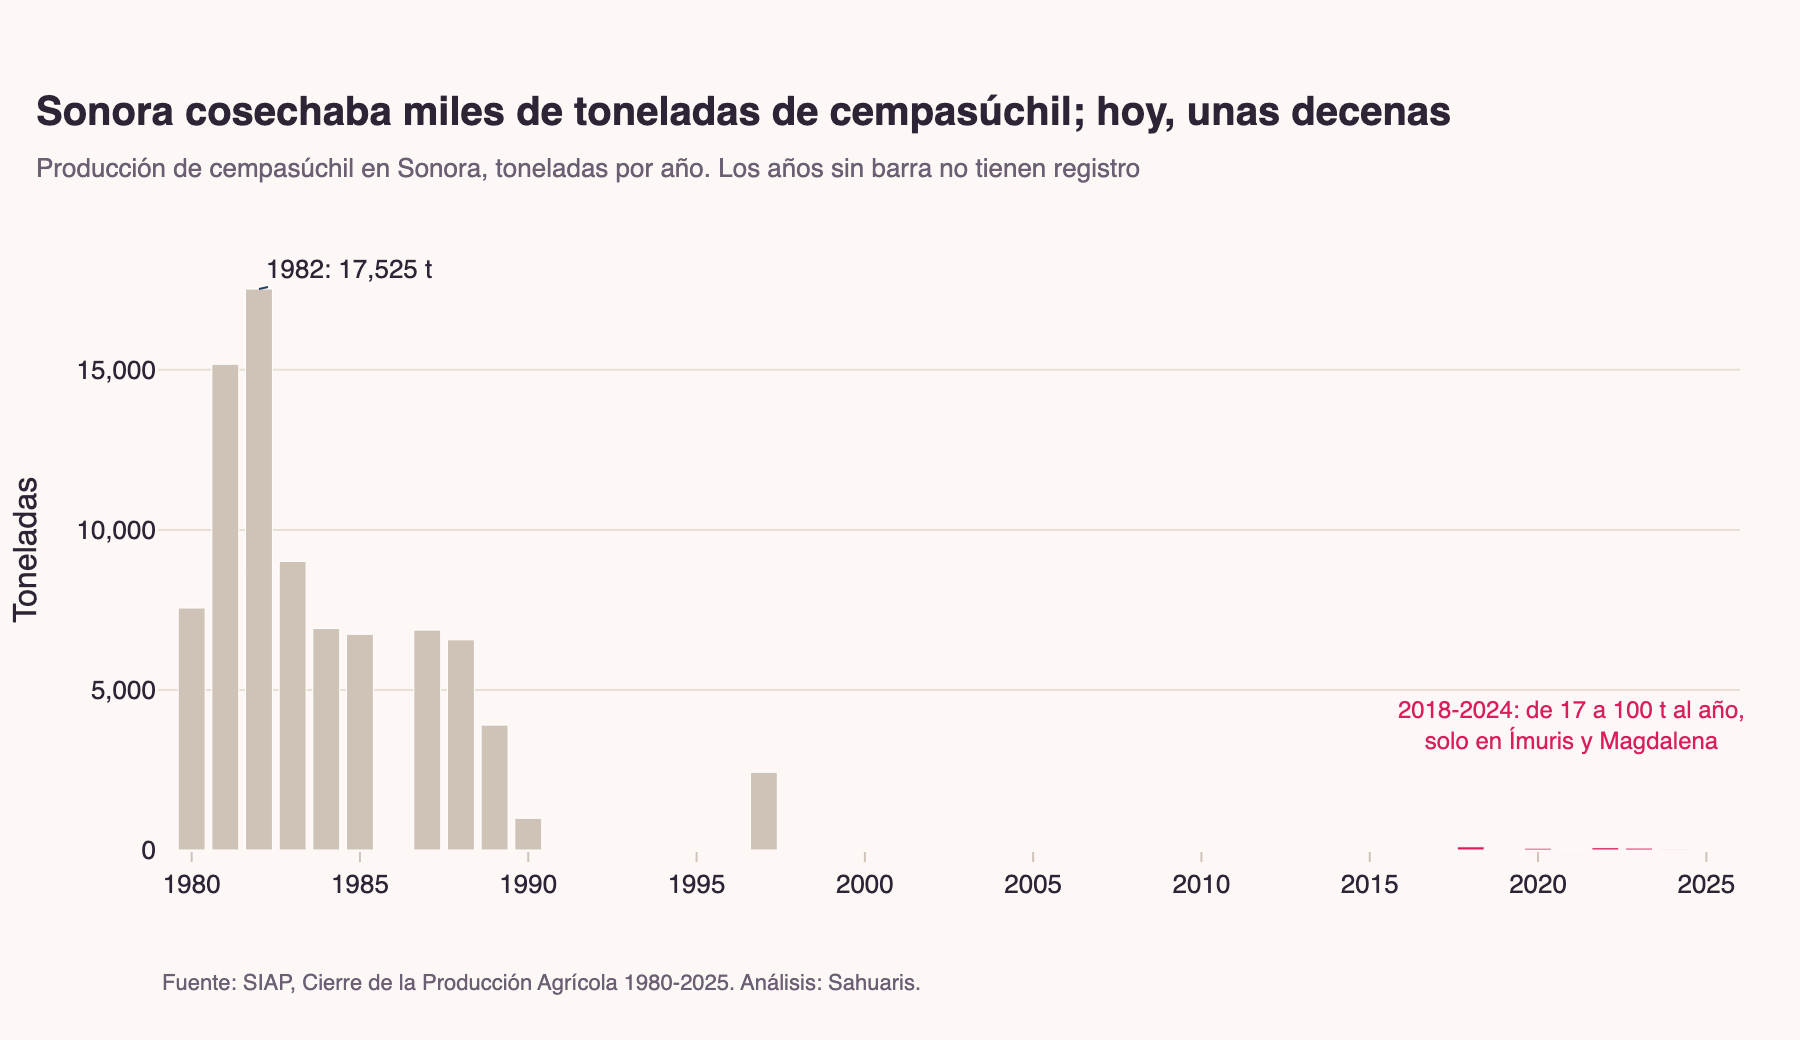

In [6]:
serie = son_anual["volumenproduccion"].reindex(range(1980, 2026))
fig = go.Figure(go.Bar(
    x=serie.index, y=serie.values,
    marker_color=[tema.PROTAGONISTA if a >= 2018 else tema.NEUTRO for a in serie.index],
    hovertemplate="%{x}: %{y:,.1f} t<extra></extra>",
))
fig.add_annotation(x=pico, y=serie.loc[pico], text=f"{pico}: {serie.loc[pico]:,.0f} t", showarrow=True, arrowhead=0, ax=45, ay=-10)
fig.add_annotation(x=2021, y=serie.max() * 0.22, text=f"2018-2024: de {recientes.min():.0f} a {recientes.max():.0f} t al año,<br>solo en Ímuris y Magdalena",
                   showarrow=True, arrowhead=0, ax=0, ay=0, xanchor="center", font=dict(size=12, color=tema.PROTAGONISTA))
fig.update_layout(
    title=tema.titulo("Sonora cosechaba miles de toneladas de cempasúchil; hoy, unas decenas",
                      "Producción de cempasúchil en Sonora, toneladas por año. Los años sin barra no tienen registro"),
    xaxis=dict(title="", range=[1979, 2026]), yaxis=dict(title="Toneladas", tickformat=","), height=520, showlegend=False,
)
tema.nota_fuente(fig, FUENTE_SIAP)
tema.mostrar(fig, "03_sonora_toneladas", alto=520)

In [7]:
son_anual.to_csv(config.DIR_PROCESSED / "sonora_anual.csv")